<div dir="rtl">

# کارگاه جلسه ۲۹ — ارزیابی و تفسیر خوشه‌ها

این دفترچه ابزارهایی را نشان می‌دهد که در جزوه نیامده‌اند و تمرین عملی کلاس را با پاسخ دارد. نوشتن این کدها در امتحان پرسیده نمی‌شود.

## ۱. رویکرد امتیازدهی RFM با پنجک‌ها

هر شاخص با `pd.qcut` به پنج دسته هم‌فراوانی تقسیم و امتیاز ۱ تا ۵ می‌گیرد (برای تازگی برعکس: خرید اخیرتر امتیاز بیشتر). چون تکرار مقادیر تکراری زیادی دارد، ابتدا با `rank(method="first")` رتبه‌بندی می‌کنیم.

</div>

In [1]:
import numpy as np
import pandas as pd

url = "https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/retail-data/all/online-retail-dataset.csv"
tx = pd.read_csv(url).dropna(subset=["CustomerID"])
tx = tx[~tx["InvoiceNo"].astype(str).str.startswith("C") & (tx["Quantity"] > 0) & (tx["UnitPrice"] > 0)].copy()
tx["InvoiceDate"] = pd.to_datetime(tx["InvoiceDate"], format="%m/%d/%Y %H:%M")
tx["amount"] = tx["Quantity"] * tx["UnitPrice"]
ref = tx["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = tx.groupby("CustomerID").agg(recency=("InvoiceDate", lambda d: (ref - d.max()).days),
                                   frequency=("InvoiceNo", "nunique"), monetary=("amount", "sum"))

score = pd.DataFrame({
    "R": pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int),
    "F": pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int),
    "M": pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)})
score["RFM"] = score["R"].astype(str) + score["F"].astype(str) + score["M"].astype(str)
print(score["RFM"].value_counts().head(5))
champions = score["RFM"] == "555"
print(f"555 customers={champions.sum()}  revenue share={rfm.loc[champions, 'monetary'].sum() / rfm['monetary'].sum():.1%}")

RFM
555    348
111    184
455    173
121    154
112    128
Name: count, dtype: int64
555 customers=348  revenue share=43.8%


<div dir="rtl">

## ۲. نمودار مار (Snake Plot)

میانگین استانداردشده هر شاخص در هر بخش را به‌صورت خط رسم می‌کنیم؛ بخش‌ها در یک نگاه مقایسه می‌شوند.

</div>

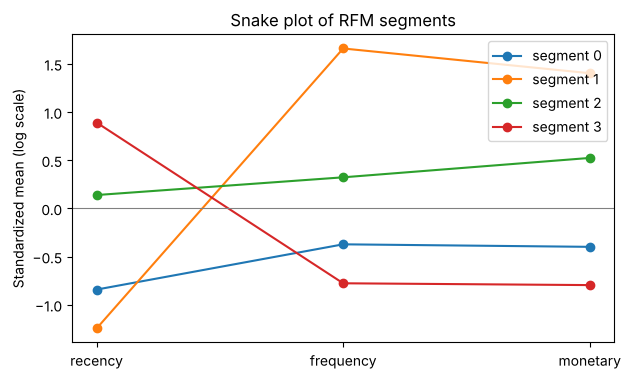

In [2]:
import numpy as np
import pandas as pd

url = "https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/retail-data/all/online-retail-dataset.csv"
tx = pd.read_csv(url).dropna(subset=["CustomerID"])
tx = tx[~tx["InvoiceNo"].astype(str).str.startswith("C") & (tx["Quantity"] > 0) & (tx["UnitPrice"] > 0)].copy()
tx["InvoiceDate"] = pd.to_datetime(tx["InvoiceDate"], format="%m/%d/%Y %H:%M")
tx["amount"] = tx["Quantity"] * tx["UnitPrice"]
ref = tx["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = tx.groupby("CustomerID").agg(recency=("InvoiceDate", lambda d: (ref - d.max()).days),
                                   frequency=("InvoiceNo", "nunique"), monetary=("amount", "sum"))
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans

Z = make_pipeline(FunctionTransformer(np.log1p), StandardScaler()).fit_transform(rfm)
seg = KMeans(4, n_init=10, random_state=42).fit_predict(Z)
snake = pd.DataFrame(Z, columns=["recency", "frequency", "monetary"]).groupby(seg).mean()
fig, ax = plt.subplots(figsize=(7, 4))
for s, row in snake.iterrows():
    ax.plot(row.index, row.values, "o-", label=f"segment {s}")
ax.axhline(0, color="gray", lw=0.8)
ax.set(ylabel="Standardized mean (log scale)", title="Snake plot of RFM segments")
ax.legend()
plt.show()

<div dir="rtl">

## تمرین عملی کلاس (۳۰ دقیقه): بخش‌بندی مشتریان فروشگاه

با همان داده Online Retail و جدول RFM:

1. دو ویژگی تکمیلی برای هر مشتری بسازید: **تعداد کالاهای متمایز** خریداری‌شده (`StockCode`) و **میانگین مبلغ هر فاکتور**.
2. پنج ویژگی را با `log1p` و `StandardScaler` آماده کنید و برای k از ۲ تا ۸ ضریب نیم‌رخ، دیویس-بولدین و کالینسکی-هاراباز را جدول کنید.
3. با k منتخب، پایداری را با ۲۰ نمونه بوت‌استرپ بسنجید.
4. پروفایل بخش‌ها (تعداد، میانه پنج ویژگی و سهم درآمد) را بسازید و برای هر بخش نام و اقدام پیشنهاد دهید.
5. بخش‌های خوشه‌بندی را با بخش «۵۵۵» رویکرد امتیازدهی مقایسه کنید: مشتریان ۵۵۵ در کدام بخش‌ها هستند؟

</div>

In [3]:
# Write your solution here

<div dir="rtl">

### پاسخ تمرین

</div>

In [4]:
import numpy as np
import pandas as pd

url = "https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/retail-data/all/online-retail-dataset.csv"
tx = pd.read_csv(url).dropna(subset=["CustomerID"])
tx = tx[~tx["InvoiceNo"].astype(str).str.startswith("C") & (tx["Quantity"] > 0) & (tx["UnitPrice"] > 0)].copy()
tx["InvoiceDate"] = pd.to_datetime(tx["InvoiceDate"], format="%m/%d/%Y %H:%M")
tx["amount"] = tx["Quantity"] * tx["UnitPrice"]
ref = tx["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = tx.groupby("CustomerID").agg(recency=("InvoiceDate", lambda d: (ref - d.max()).days),
                                   frequency=("InvoiceNo", "nunique"), monetary=("amount", "sum"))
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

# 1. Extra features
extra = tx.groupby("CustomerID").agg(products=("StockCode", "nunique"))
feat = rfm.join(extra)
feat["basket"] = feat["monetary"] / feat["frequency"]

# 2. Internal measures
Z = make_pipeline(FunctionTransformer(np.log1p), StandardScaler()).fit_transform(feat)
rows = []
for k in range(2, 9):
    lab = KMeans(k, n_init=10, random_state=42).fit_predict(Z)
    rows.append({"k": k, "silhouette": silhouette_score(Z, lab), "DB": davies_bouldin_score(Z, lab),
                 "CH": calinski_harabasz_score(Z, lab)})
print(pd.DataFrame(rows).set_index("k").round(3).T.to_string())

# 3. Stability for the chosen k
k = 4
full = KMeans(k, n_init=10, random_state=42).fit(Z).labels_
rng = np.random.default_rng(42)
aris = []
for b in range(20):
    idx = rng.integers(0, len(Z), len(Z))
    boot = KMeans(k, n_init=10, random_state=b).fit(Z[idx])
    aris.append(adjusted_rand_score(full, boot.predict(Z)))
print(f"bootstrap ARI mean={np.mean(aris):.2f}  min={np.min(aris):.2f}")

# 4. Profile
feat["segment"] = full
profile = feat.groupby("segment").median().round(1)
profile["n"] = feat["segment"].value_counts().sort_index()
profile["revenue_%"] = (feat.groupby("segment")["monetary"].sum() / feat["monetary"].sum() * 100).round(1)
print(profile.sort_values("monetary", ascending=False))

# 5. Where are the 555 customers?
R = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
F = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
M = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
is555 = (R == 5) & (F == 5) & (M == 5)
print(feat.loc[is555, "segment"].value_counts())

k                  2         3         4         5         6         7         8
silhouette     0.347     0.253     0.238     0.233     0.219     0.213     0.212
DB             1.101     1.277     1.294     1.257     1.270     1.310     1.272
CH          2918.269  2329.923  2029.437  1846.911  1695.434  1570.593  1476.935


bootstrap ARI mean=0.88  min=0.81
         recency  frequency  monetary  products  basket     n  revenue_%
segment                                                                 
2           12.0        9.0    3541.3     123.0   420.3   864       71.3
0           23.0        3.0     848.4      50.0   245.3  1202       12.7
1          117.0        1.0     615.6      29.0   406.5  1196       13.5
3          143.0        1.0     178.1      10.0   142.3  1076        2.4
segment
2    346
0      2
Name: count, dtype: int64


<div dir="rtl">

### پاسخ‌های کلیدی

- **امتیازدهی:** ۳۴۸ مشتری امتیاز «۵۵۵» دارند (حدود ۸ درصد مشتریان) و ۴۳.۸ درصد درآمد را می‌سازند.
- **معیارهای درونی با پنج ویژگی:** هر سه معیار k برابر **۲** را ترجیح می‌دهند (نیم‌رخ ۰.۳۴۷) و از ۳ به بعد تقریباً هموارند (۰.۲۱ تا ۰.۲۵). دو بخش فقط فعال و غیرفعال را جدا می‌کند؛ k برابر ۴ را برای اقدام‌پذیری انتخاب کردیم. نیم‌رخ‌ها پایین‌تر از جزوه است: ویژگی‌های بیشتر لزوماً جدایی بیشتری نمی‌دهند.
- **پایداری چهار بخش:** میانگین ARI بوت‌استرپ ۰.۸۸ و کمینه ۰.۸۱؛ قابل قبول.

| بخش | تعداد | تازگی | تکرار | ارزش | کالای متمایز | مبلغ هر فاکتور | سهم درآمد | نام و اقدام |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| ۲ | 864 | 12 | 9 | 3541 | 123 | 420 | ۷۱.۳٪ | قهرمانان؛ برنامه وفاداری |
| ۰ | 1202 | 23 | 3 | 848 | 50 | 245 | ۱۲.۷٪ | فعال‌های در حال رشد؛ تشویق به خرید مکرر |
| ۱ | 1196 | 117 | 1 | 616 | 29 | 407 | ۱۳.۵٪ | خریداران یک‌باره با سبد بزرگ؛ کمپین بازگشت هدفمند |
| ۳ | 1076 | 143 | 1 | 178 | 10 | 142 | ۲.۴٪ | کم‌ارزش ازدست‌رفته؛ هزینه کم |

- ویژگی «مبلغ هر فاکتور» بخشی تازه ساخت (بخش ۱): مشتریانی که یک بار با سبد بزرگ خریده‌اند و برنگشته‌اند؛ برگرداندن آن‌ها از بخش ۳ بسیار ارزشمندتر است.
- از ۳۴۸ مشتری «۵۵۵»، ۳۴۶ نفر در بخش قهرمانان‌اند: دو رویکرد هم‌خوان‌اند، اما خوشه‌بندی بخش قهرمانان را بزرگ‌تر (۸۶۴ نفر) و بخش‌های دیگر را با ویژگی‌های تکمیلی متمایزتر کرد.

</div>